In [1]:
import os
import sys
from pathlib import Path

project_root = Path.cwd().parent if Path.cwd().name == "other" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
    
import datetime as dt

from benchmark import benchmark
from examples import example_a_mf as example_a

output_dir = Path("output") / "exp_a"

os.makedirs(output_dir, exist_ok=True)
os.makedirs(output_dir / "images", exist_ok=True)

end_date = dt.datetime(2026, 8, 1)

weights, in_sample, out_of_sample, periods, metrics, n = benchmark(
    config_module=example_a, output=output_dir, end_date=end_date, verbose=False
)


In [2]:
import numpy as np

reference_portfolios = {
    "World Equity 40%": np.array([0.24, 0.12, 0.04, 0.60]),
    "Classic 40/60 US-Centric": np.array([0.40, 0.00, 0.00, 0.60]), 
    "Naive Equal Weight": np.array([0.25, 0.25, 0.25, 0.25,]),
    "Equal Risk Contribution": np.array([0.12, 0.10, 0.08, 0.7,]), 
}

reference_colors = {
    "World Equity 40%": "orange",
    "Classic 40/60 US-Centric": "red",
    "Naive Equal Weight": "green",
    "Equal Risk Contribution": "purple",
}


In [3]:
from src.metrics.cvar import CVaR

CVAR_ALPHA = 0.05
cvar_metric = CVaR(alpha=CVAR_ALPHA)

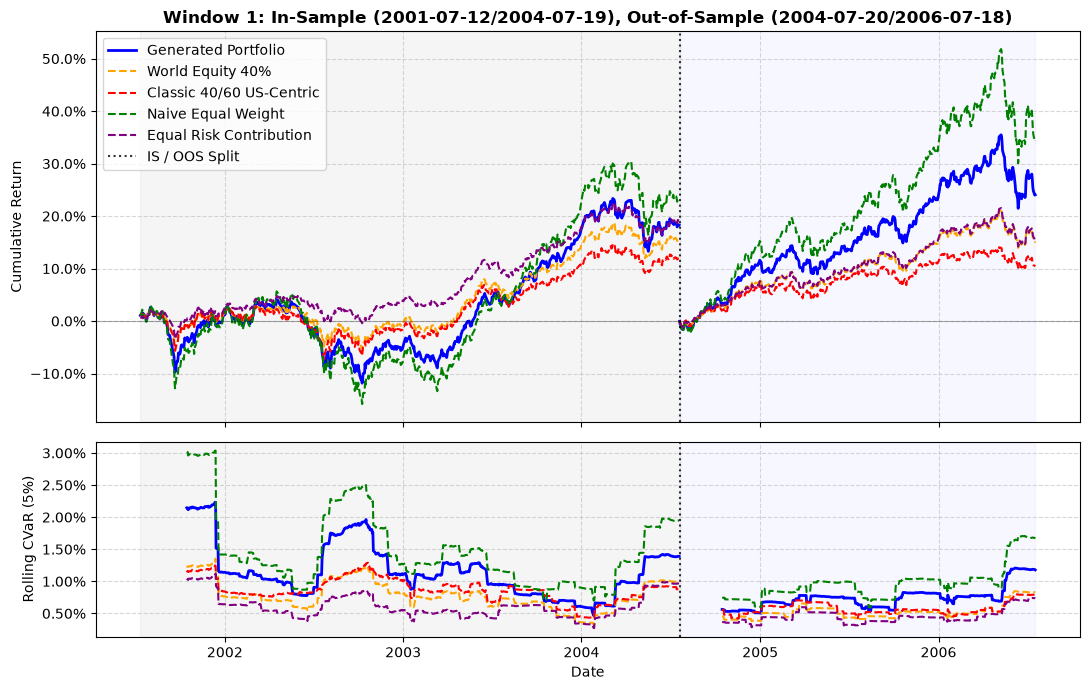

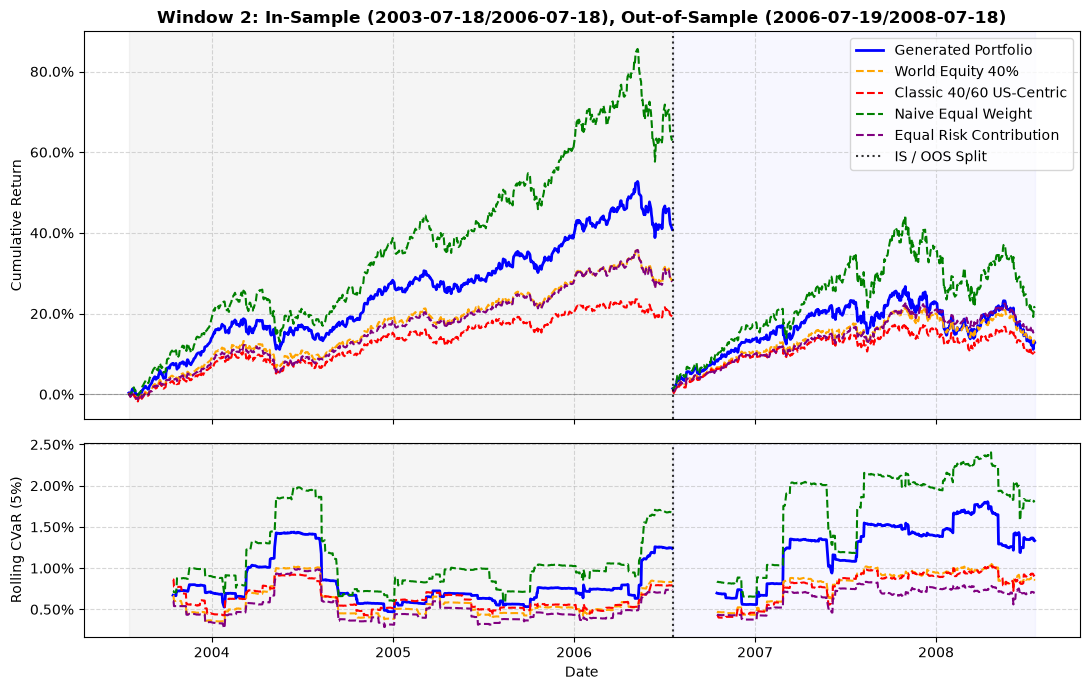

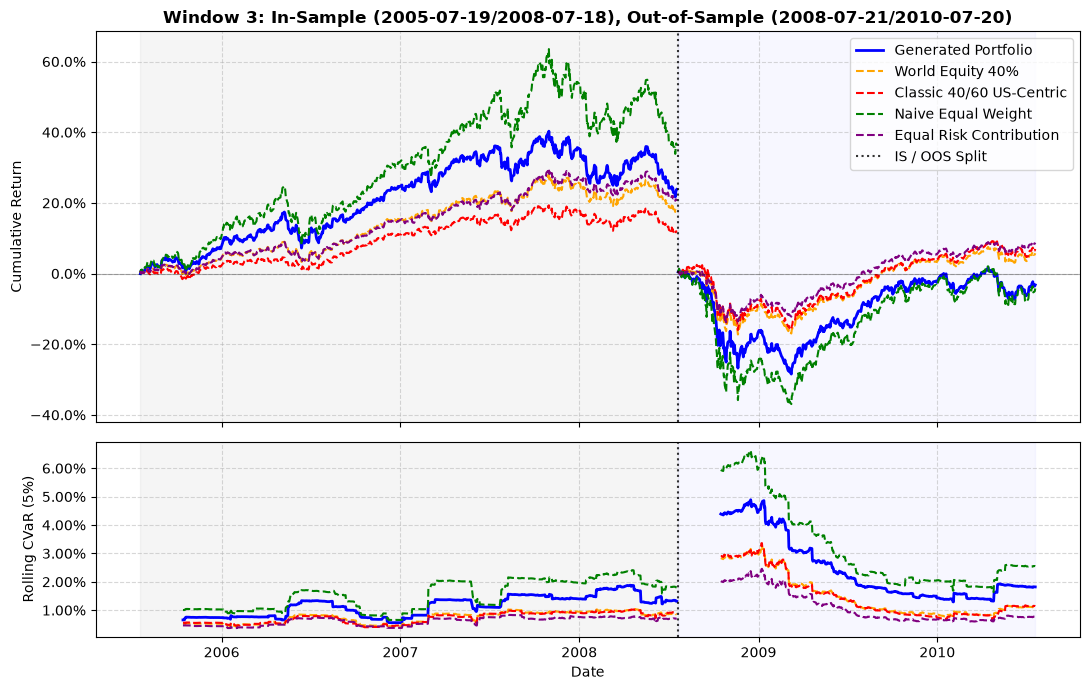

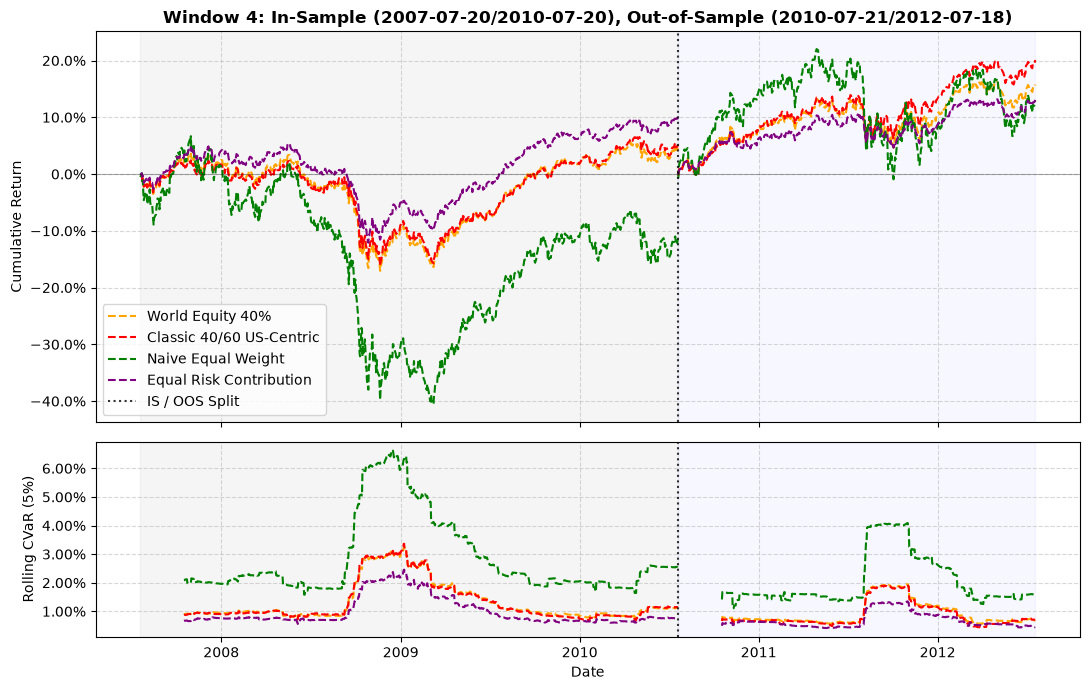

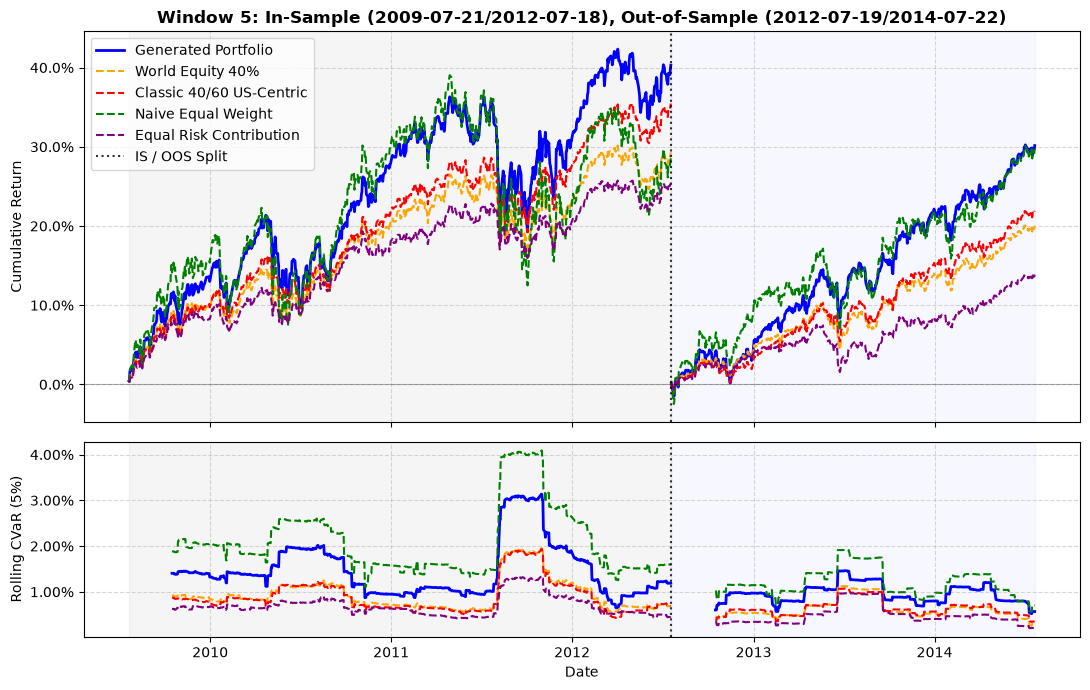

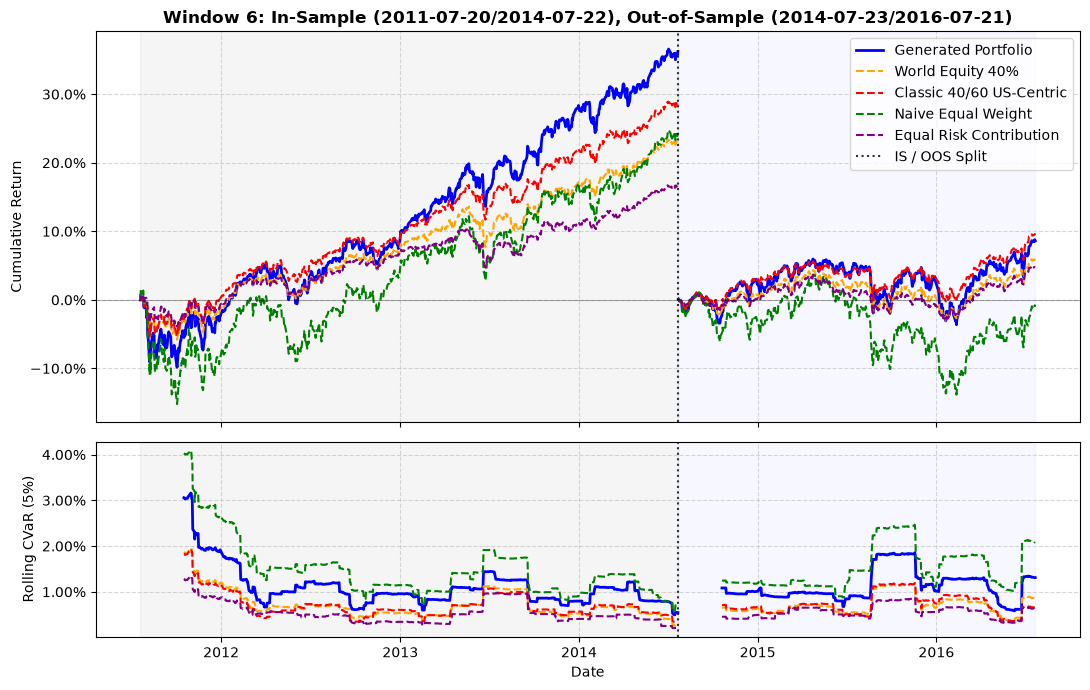

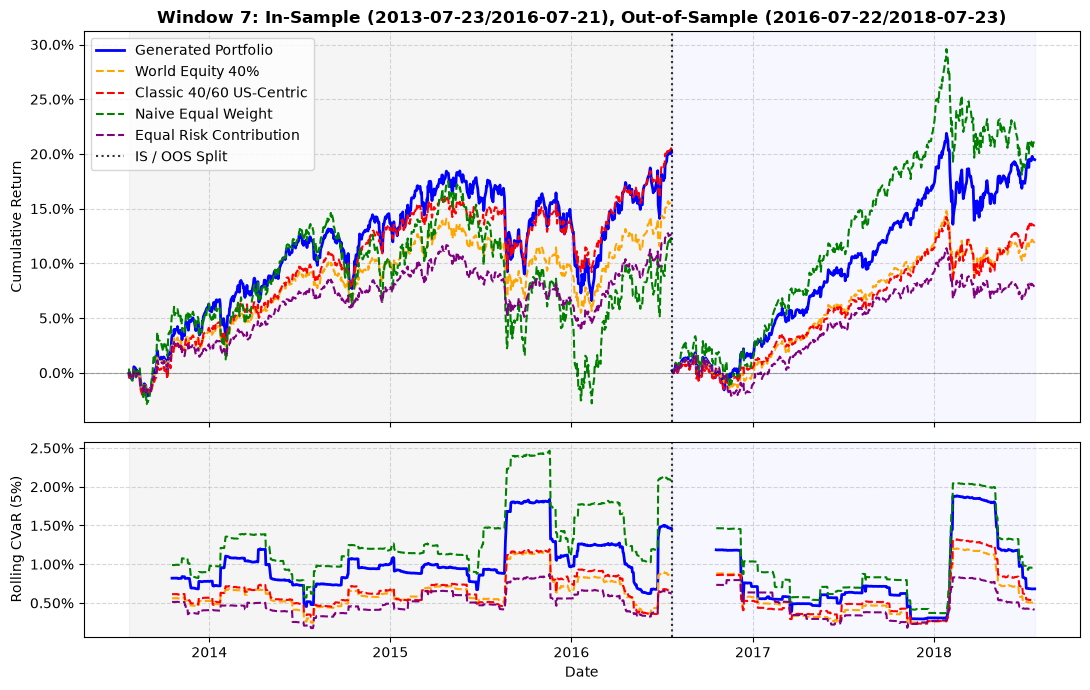

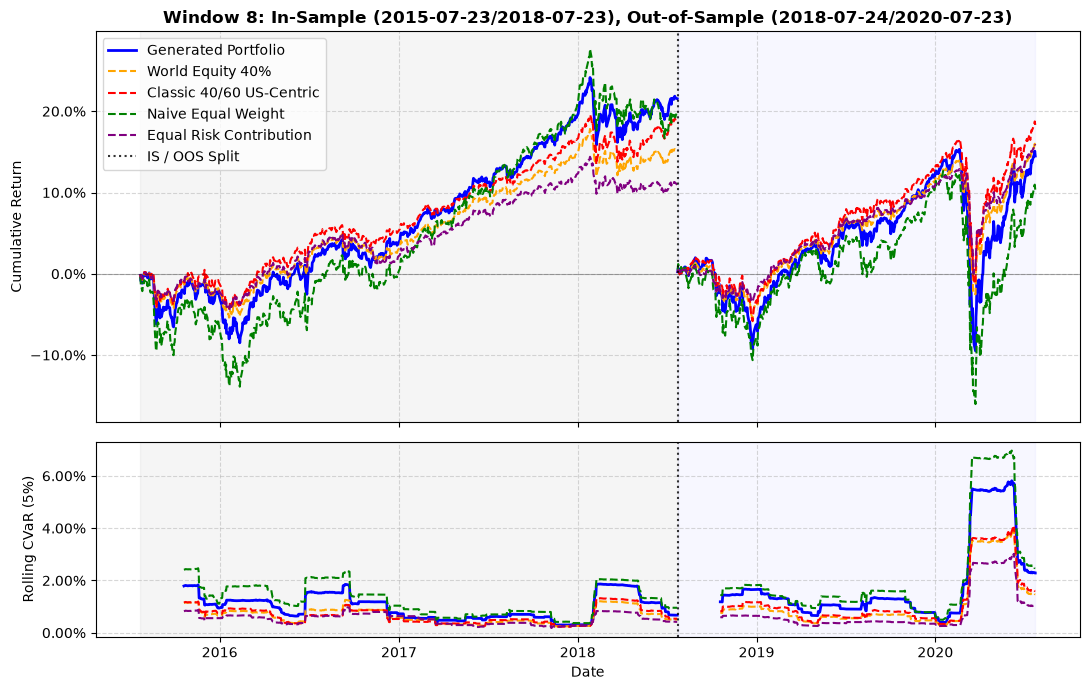

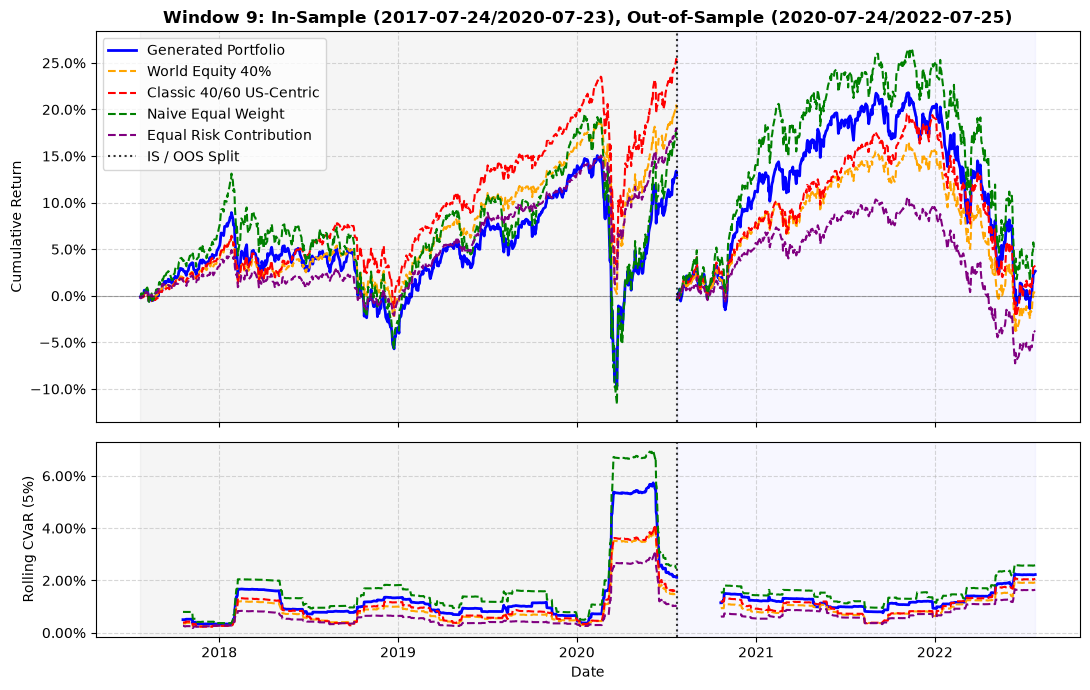

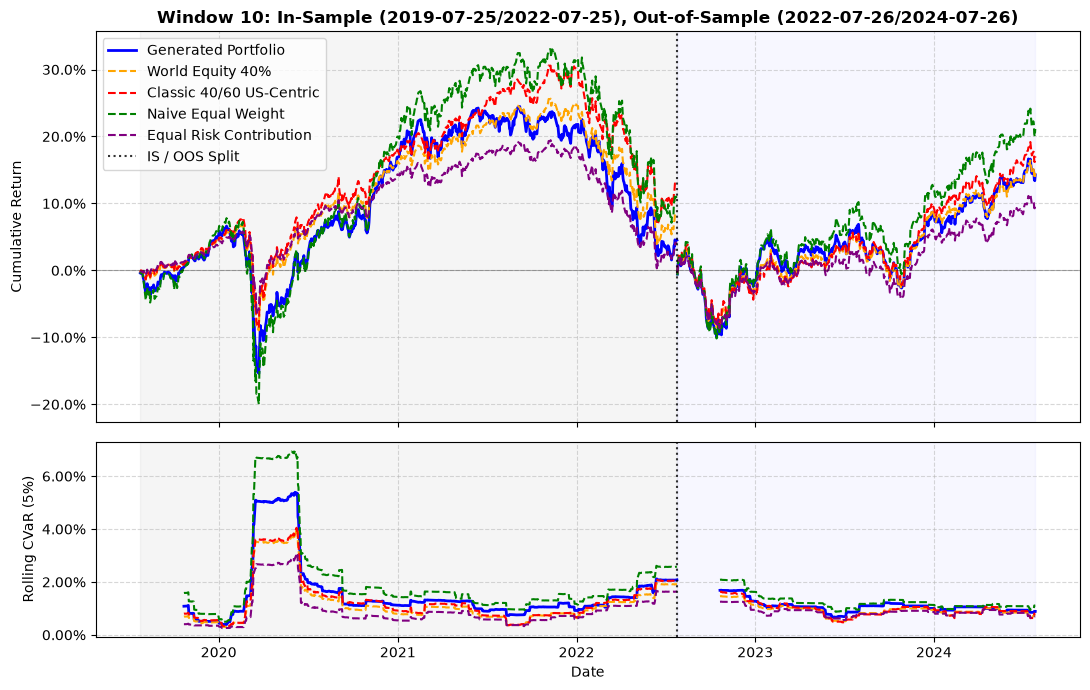

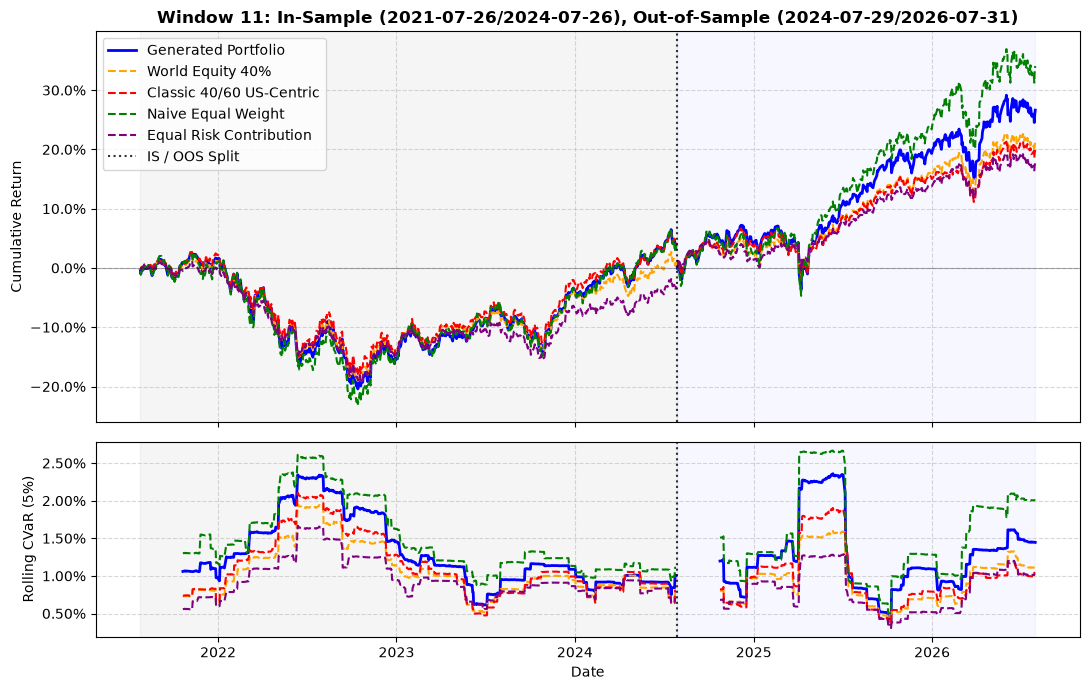

In [4]:
from other.utils import compute_rolling_cvar, display_and_save

display_and_save(
    n_windows=n,
    periods=periods,
    weights=weights,
    out_of_sample=out_of_sample,
    reference_portfolios=reference_portfolios,
    reference_colors=reference_colors,
    output_dir=output_dir,
    compute_metric=compute_rolling_cvar,
    metric=cvar_metric,
    alpha=CVAR_ALPHA,
    in_sample=in_sample
)

In [5]:
from other.utils import save_metrics

save_metrics(
    metrics=metrics,
    n_windows=n,
    config=example_a,
    reference_portfolios=reference_portfolios,
    in_sample=in_sample,
    out_of_sample=out_of_sample,
    output_dir=output_dir,
)

Metrics for Window 1:
    Window                 Portfolio Metric  InSample  OutOfSample  Difference
0        1       Generated Portfolio   CAGR  0.057619     0.113780    0.056161
1        1       Generated Portfolio   CVaR  0.012457     0.010152   -0.002305
2        1       Generated Portfolio  Omega  1.583898     2.750597    1.166700
3        1       Generated Portfolio    ENC  3.340098     3.340098    0.000000
4        1       Generated Portfolio    ENB  1.360092     1.518515    0.158423
5        1          World Equity 40%   CAGR  0.049391     0.072091    0.022701
6        1          World Equity 40%   CVaR  0.008101     0.006758   -0.001344
7        1          World Equity 40%  Omega  1.740487     2.684564    0.944077
8        1          World Equity 40%    ENC  2.306273     2.306273    0.000000
9        1          World Equity 40%    ENB  2.000646     2.230645    0.229999
10       1  Classic 40/60 US-Centric   CAGR  0.037978     0.050796    0.012819
11       1  Classic 40/60 US-C